In [1]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.visualisation.quinex_visualisation import QuinexVisualisation

In [2]:
visualisation = QuinexVisualisation()

In [ ]:
import ast

def contains_irena(ref, term="IRENA"):
    if isinstance(ref, str):
        try:
            ref = ast.literal_eval(ref)
        except Exception:
            return False
    if isinstance(ref, list):
        return any(
            "IRENA" in (d.get("title", "") or "") or "IRENA" in (d.get("venue", "") or "")
            for d in ref
        )
    return False

### **Import Results**

#### **CAPEX**

In [3]:
cost_capex = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_capex_new.xlsx")
cost_capex["entity_mapping"].value_counts().head(20)

entity_mapping
PV                      357
Electrolyzer            199
Wind                    185
Bioenergy                64
Offshore Wind            45
Nuclear                  43
Hydrogen                 39
Battery                  26
Onshore Wind             26
Hydropower               26
Geothermal               19
Natural Gas              15
Coal                     14
Lithium-Ion Battery       9
Green Hydrogen            6
Hybrid Energy System      2
Lead Acid Battery         2
Name: count, dtype: int64

In [21]:
cost_capex[cost_capex["references"].apply(contains_irena)]

,Unnamed: 0,publication_year,DOI,classification,entity,property,quantity_text,value_normalized_old,unit_normalized_old,quantity_normalized,...,unit_dimension_old,value_normalized,unit_normalized,unit_dimension,references,entity_mapping,entity_base_mapping,property_mapping,property_base_mapping,value_converted
466,466,2021,10.3390/en14123437,"{'rational': 'arbitrary', 'system': 'model', 'type': 'specification'}",PV plants,total installed costs (TIC),NaN,760.0,"[('USD', 1.0, 'http://qudt.org/vocab/currency/USD', None), ('kW', -1.0, 'http://qudt.org/vocab/unit/KiloW', None)]","{'quantities': array([{'modifier': '=', 'unit': array([{'exponent': 1.0, 'text': 'USD', 'unit_uri': 'http://qudt.org/vocab/currency/USD', 'year': None},\n {'exponent': -1.0, 'text': 'kW', 'unit_uri': 'http://qudt.org/vocab/unit/KiloW', 'year': None}],\n dtype=object), 'value': 760.0} ],\n dtype=object), 'type': 'single_quantity'}",...,A0E0L-2I0M-1H0T3D0,760.0,"[('USD', 1, 'http://qudt.org/vocab/unit/CCY_USD', None), ('kW', -1, 'http://qudt.org/vocab/unit/KiloW', None)]",A0E0L-2I0M-1H0T3D0,"[{'title': 'IRENA. Renewable Power Generation Costs in 2019', 'venue': ''}]",PV,PV,Capital Cost,Cost,0.760
1038,1038,2023,10.1371/journal.pone.0276510,"{'rational': None, 'system': 'model', 'type': 'observation'}",PV module,initial capital cost,NaN,995.0,"[('USD', 1.0, 'http://qudt.org/vocab/currency/USD', None), ('kW', -1.0, 'http://qudt.org/vocab/unit/KiloW', None)]","{'quantities': array([{'modifier': '=', 'unit': array([{'exponent': 1.0, 'text': 'USD', 'unit_uri': 'http://qudt.org/vocab/currency/USD', 'year': None},\n {'exponent': -1.0, 'text': 'kW', 'unit_uri': 'http://qudt.org/vocab/unit/KiloW', 'year': None}],\n dtype=object), 'value': 995.0} ],\n dtype=object), 'type': 'single_quantity'}",...,A0E0L-2I0M-1H0T3D0,995.0,"[('USD', 1, 'http://qudt.org/vocab/unit/CCY_USD', None), ('kW', -1, 'http://qudt.org/vocab/unit/KiloW', None)]",A0E0L-2I0M-1H0T3D0,"[{'title': 'IRENA Renewable Power Generation Costs in', 'venue': ''}]",PV,PV,Capital Cost,Cost,0.995


In [6]:
#cost_capex["entity_mapping"].value_counts().head(20)

#### **Lifetime**

In [7]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
lifetime = df[df["property_mapping"] == "Lifetime"]
lifetime = lifetime[lifetime['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/YR'
)]
lifetime["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': 'years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]    3590
[{'exponent': 1.0, 'text': 'year', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]      196
[{'exponent': 1.0, 'text': 'yr', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]         16
[{'exponent': 1.0, 'text': 'yrs', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]        12
[{'exponent': 1.0, 'text': 'y', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]           6
[{'exponent': 1.0, 'text': 'a', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]           5
[{'exponent': 1.0, 'text': 'Years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]       4
Name: count, dtype: int64

#### **Efficiency**

In [8]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
efficiency = df[df["property_mapping"] == "Efficiency"]
efficiency = efficiency[efficiency['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
)]
efficiency["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': '%', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]          14462
[{'exponent': 1.0, 'text': 'percent', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]       61
Name: count, dtype: int64

#### **Caapcity Factor**

In [9]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
cap_factor_raw = df[df["property_mapping"] == "Capacity Factor"]
percent = cap_factor_raw[
    cap_factor_raw['unit_normalized'].apply(
        lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
    )
]

unitless = cap_factor_raw[
    cap_factor_raw['unit_normalized'].apply(
        lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/UNITLESS'
    )
]

# nur Werte zwischen 0 und 1 behalten
unitless = unitless[unitless['value_normalized'].between(0, 1)]

# auf Prozent skalieren
unitless['value_normalized'] = unitless['value_normalized'] * 100

# zusammenführen
cap_factor = pd.concat([percent, unitless], ignore_index=True)
cap_factor["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': '%', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]          1682
[{'exponent': None, 'text': None, 'unit_uri': 'http://qudt.org/vocab/unit/UNITLESS', 'year': None}]        298
[{'exponent': 1.0, 'text': 'percent', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]       9
Name: count, dtype: int64

In [23]:
cap_factor["references"].value_counts()

references
[{'title': '', 'venue': ''}]                                                                                                                    90
[{'title': 'Long-term patterns of European PV output using 30 years of validated hourly reanalysis and satellite data', 'venue': ''}]            6
[{'title': 'Using bias-corrected reanalysis to simulate current and future wind power output', 'venue': ''}]                                     5
[{'title': 'Capacity factor of wind power realized values vs. estimates', 'venue': ''}]                                                          5
[{'title': 'Off-grid electricity generation with renewable energy technologies in India: An application of HOMER', 'venue': ''}]                 4
                                                                                                                                                ..
[{'title': 'Country Analysis Executive Summary: South Korea', 'venue': ''}]                                

In [22]:
cap_factor[cap_factor["references"].apply(contains_irena)]

,publication_year,DOI,classification,entity,property,quantity_text,value_normalized,unit_normalized,quantity_normalized,quote,...,spatial_scope_refined,unit_dimension,value_normalized_adapted,unit_normalized_adapted,unit_dimension_adapted,references,entity_mapping,entity_base_mapping,property_mapping,property_base_mapping


In [11]:
cap_factor["entity_mapping"].value_counts().head(20)

entity_mapping
Wind                           751
PV                             464
Electrolyzer                   166
Offshore Wind                   99
Nuclear                         97
Onshore Wind                    88
Coal                            72
Hydropower                      54
Hydrogen                        47
Bioenergy                       45
Geothermal                      32
Natural Gas                     32
Battery                         28
Hybrid Energy System             6
Green Hydrogen                   6
Liquefied Natural Gas (LNG)      1
Lead Acid Battery                1
Name: count, dtype: int64

### **Visualize Results**

In [12]:
# Stelle das ursprüngliche cap_factor Dictionary wieder her und konvertiere es
cap_factor_dict_pv = {
    "year": list(range(2010, 2025)),
    "value": [15.0, 15.3, 15.1, 16.5, 16.6, 16.5, 16.8, 17.5, 17.9, 17.5, 16.1, 17.2, 16.9, 16.2, 17.4],
    "entity": ["PV"] * 15
}
cap_factor_dict_onshore = {
    "year": list(range(2010, 2025)),
    #"value": [29, 31, 33, 35, 36, 36, 39, 37, 36, 34],
    "value": [27, 27, 28, 28, 29, 29, 31, 33, 35, 36, 36, 39, 37, 36, 34],
    "entity": ["Onshore Wind"] * 15
}
cap_factor_dict_offshore = {
    "year": list(range(2015, 2025)),
    "value": [42, 40, 45, 39, 42, 39, 39, 41, 41, 42],
    # "value": [38, 38, 40, 44, 35, 42, 40, 45, 39, 42, 39, 39, 41, 41, 42],
    "entity": ["Offshore Wind"] * 10
}

cap_factor_additional = pd.concat([pd.DataFrame(cap_factor_dict_pv), pd.DataFrame(cap_factor_dict_onshore), pd.DataFrame(cap_factor_dict_offshore)], ignore_index=True)

In [13]:
capex_dict_pv = {
    "year": list(range(2010, 2025)),
    "value": [5.284, 4.659, 3.537, 3.107, 2.849, 2.140, 1.958, 1.683, 1.438, 1.188, 1.044, 0.973, 0.930, 0.766, 0.691],
    "entity": ["PV"] * 15
}

capex_additional_onshore = {
    "year": list(range(2010, 2025)),
    "value": [2.324, 2.278, 2.165, 2.234, 2.147, 1.956, 1.960, 1.963, 1.865, 1.766, 1.589, 1.506, 1.353, 1.187, 1.041],
    "entity": ["Onshore Wind"] * 15
}

# capex_additional_offshore = {
#     "year": list(range(2010, 2025)),
#     "value": [5.518, 6.343, 5.651, 5.819, 6.247, 6.265, 4.933, 5.531, 4.944, 4.354, 3.87, 3.229, 3.518, 2.867, 2.852],
#     "entity": ["Offshore Wind"] * 15
# }
capex_additional_offshore = {
    "year": list(range(2019, 2025)),
    "value": [4.354, 3.87, 3.229, 3.518, 2.867, 2.852],
    "entity": ["Offshore Wind"] * 6
}

capex_additional = pd.concat([pd.DataFrame(capex_dict_pv), pd.DataFrame(capex_additional_onshore), pd.DataFrame(capex_additional_offshore)], ignore_index=True)

In [14]:
lcoe_dict_pv = {
    "year": list(range(2010, 2025)),
    "value": [0.417, 0.350, 0.260, 0.200, 0.183, 0.135, 0.118, 0.093, 0.079, 0.069, 0.061, 0.055, 0.051, 0.042, 0.043],
    "entity": ["PV"] * 15
}

lcoe_additional_onshore = {
    "year": list(range(2010, 2025)),
    "value": [0.113, 0.107, 0.098, 0.098, 0.088, 0.076, 0.070, 0.066, 0.056, 0.049, 0.041, 0.036, 0.034, 0.033, 0.034],
    "entity": ["Onshore Wind"] * 15
}

lcoe_additional_offshore = {
    "year": list(range(2010, 2025)),
    "value": [0.208, 0.215, 0.185, 0.156, 0.190, 0.155, 0.128, 0.117, 0.114, 0.095, 0.091, 0.082, 0.081, 0.076, 0.079],
    "entity": ["Offshore Wind"] * 15
}

lcoe_additional = pd.concat([pd.DataFrame(lcoe_dict_pv), pd.DataFrame(lcoe_additional_onshore), pd.DataFrame(lcoe_additional_offshore)], ignore_index=True)

C:\Users\m.gorres\AppData\Local\Temp\ipykernel_17084\1106548488.py:85: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


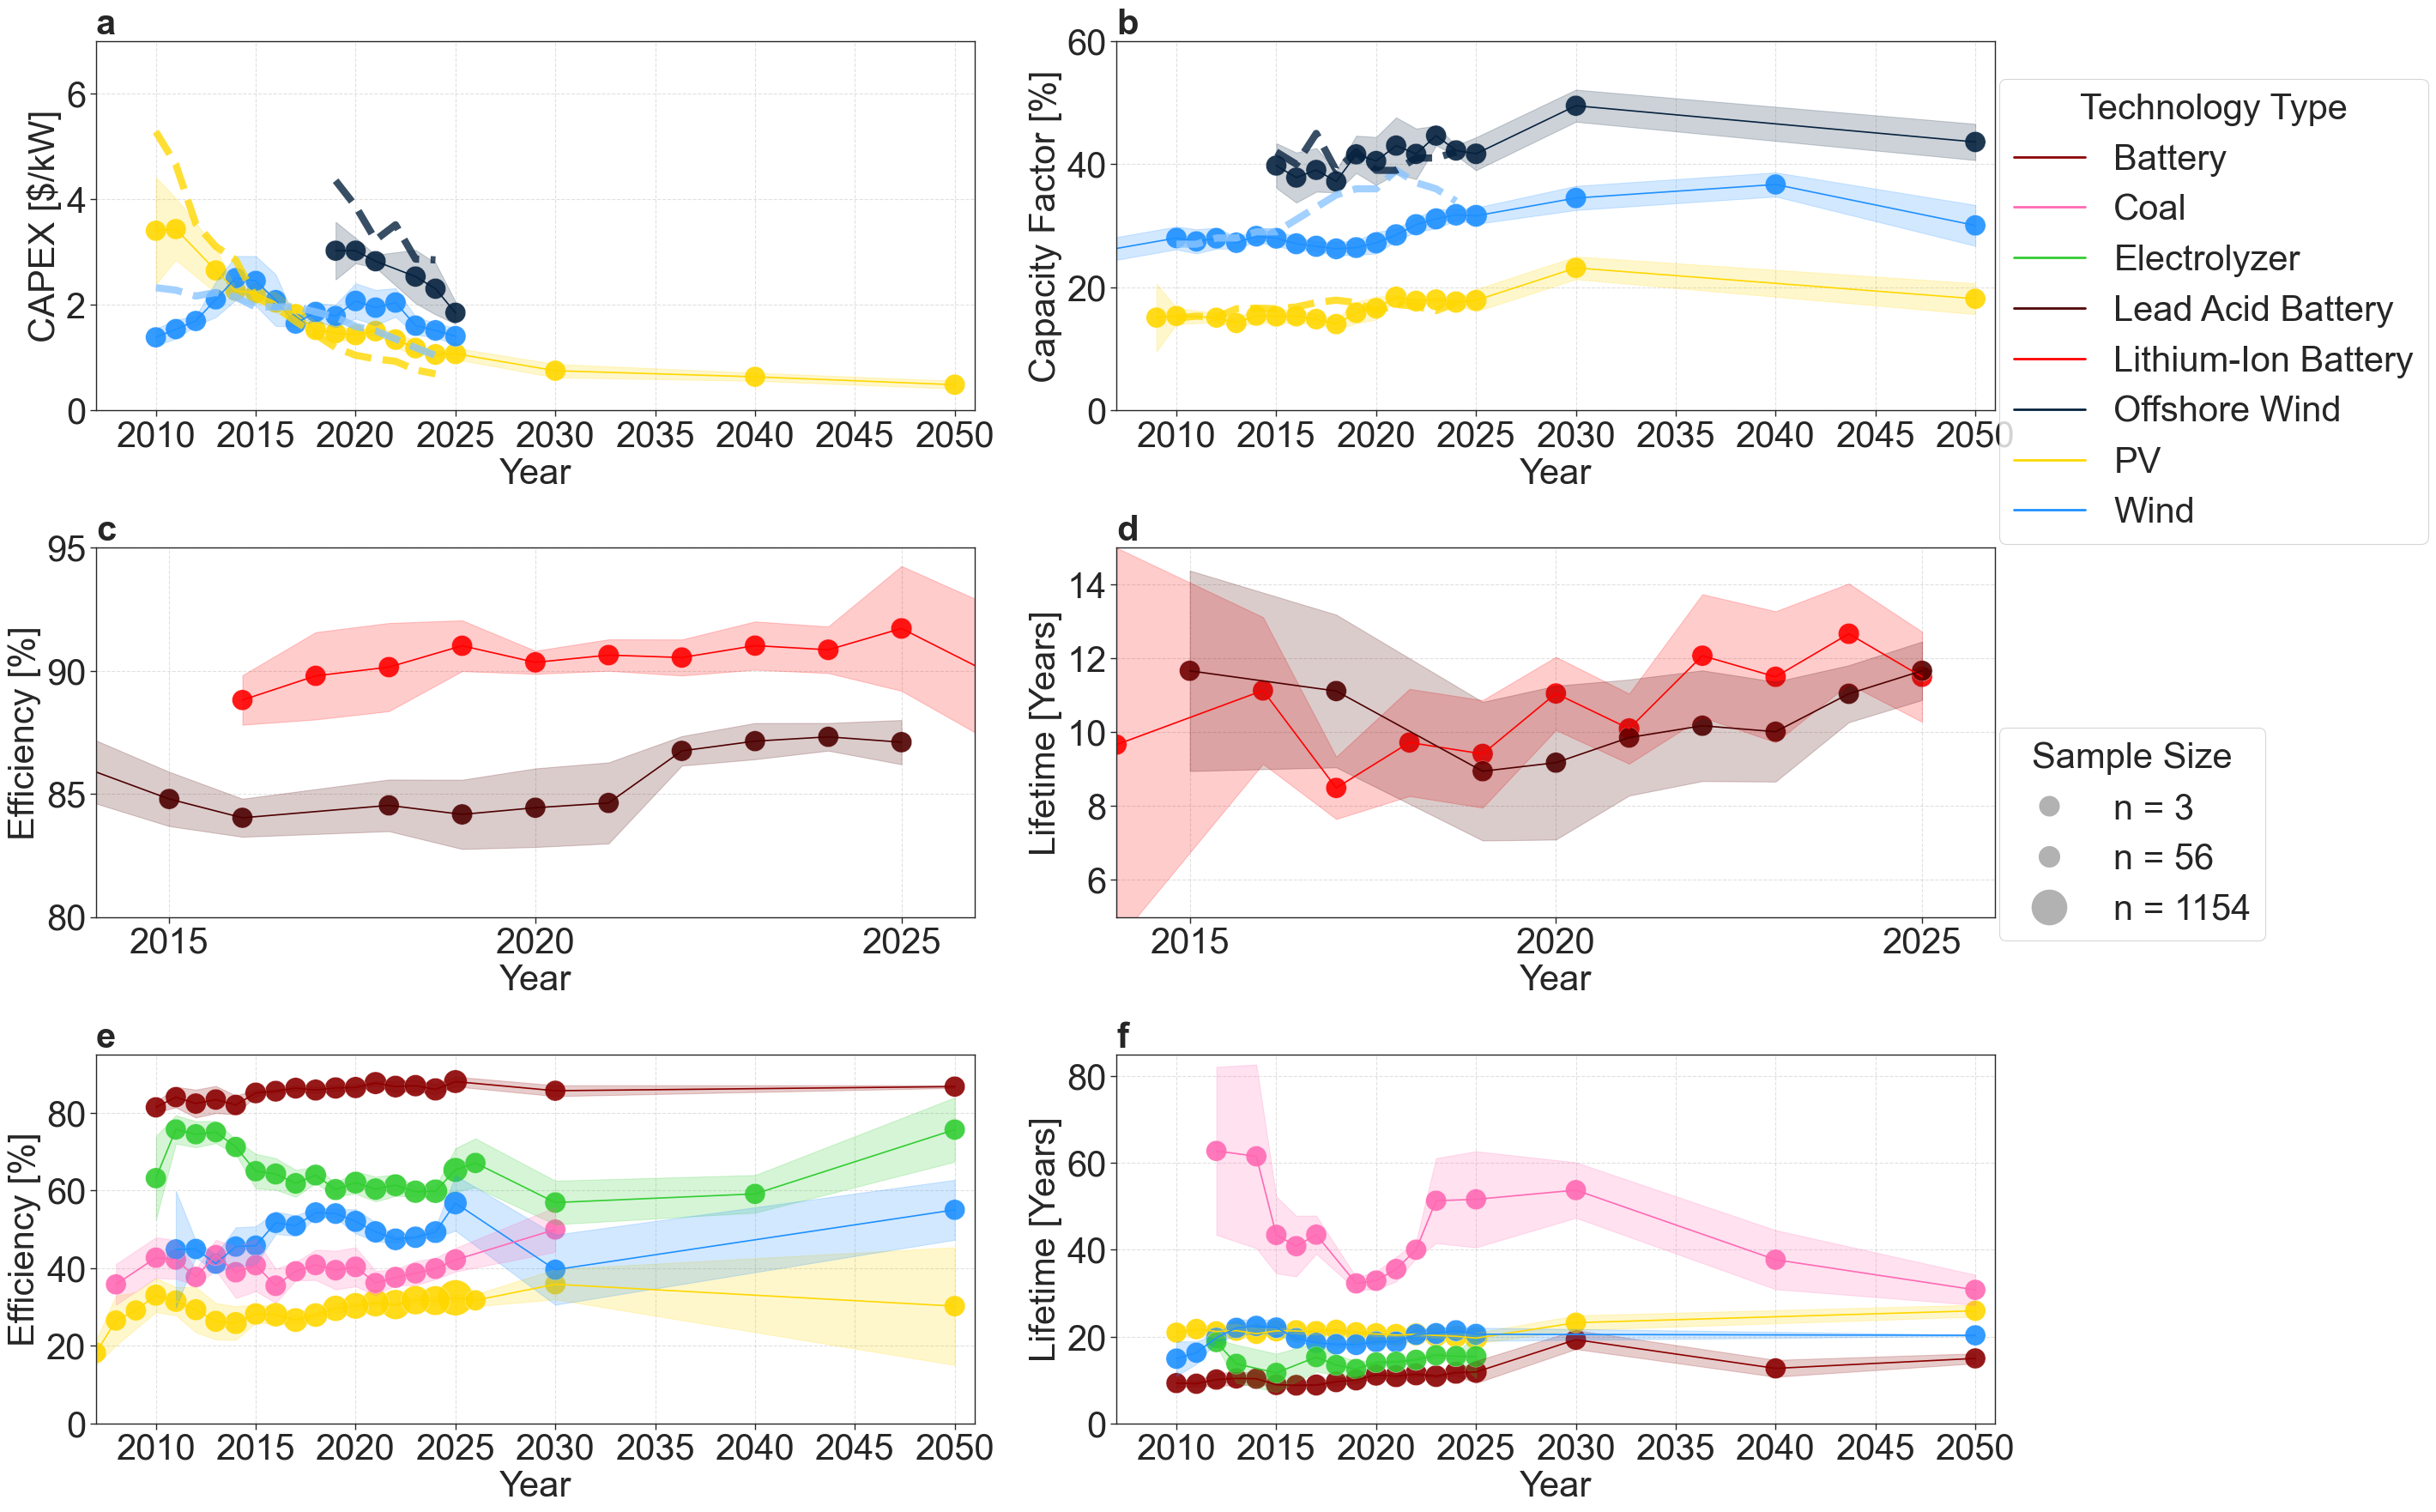

In [15]:
cost_capex['entity_mapping'] = cost_capex['entity_mapping'].replace({
    'Onshore Wind': 'Wind'
})
cap_factor['entity_mapping'] = cap_factor['entity_mapping'].replace({
    'Onshore Wind': 'Wind'
})


data = [
    {
    'df': cost_capex[cost_capex["entity_mapping"].isin(['PV', 'Offshore Wind', 'Wind'])],
    'entity_col': 'entity_mapping',
    'value_col': 'value_converted',
    'ylabel': 'CAPEX [$/kW]', 
    'title': 'a',
    'additional_data': capex_additional,
    'year_range': (2007, 2051),
    'y_range': (0, 7),
    },
    {
    'df': cap_factor[cap_factor["entity_mapping"].isin(['PV', 'Offshore Wind', 'Wind'])],
    'entity_col': 'entity_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Capacity Factor [%]', 
    'title': 'b',
    'additional_data': cap_factor_additional,
    'year_range': (2007, 2051),
    'y_range': (0, 60),
    },
    {
    'df': efficiency[efficiency["entity_mapping"].isin(['Lithium-Ion Battery', 'Lead Acid Battery'])],
    'entity_col': 'entity_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Efficiency [%]', 
    'title': 'c',
    'year_range': (2014, 2026),
    'y_range': (80, 95),
    },
    {
    'df': lifetime[lifetime["entity_mapping"].isin(['Lithium-Ion Battery', 'Lead Acid Battery'])],
    'entity_col': 'entity_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Lifetime [Years]',
    'title': 'd',
    'year_range': (2014, 2026),
    'y_range': (5, 15),
    },
    {
    'df': efficiency[efficiency["entity_base_mapping"].isin(['PV', 'Battery', 'Wind', 'Electrolyzer', 'Coal'])],
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Efficiency [%]', 
    'title': 'e',
    'year_range': (2007, 2051),
    'y_range': (0, 95),
    },
    {
    'df': lifetime[lifetime["entity_base_mapping"].isin(['PV', 'Battery', 'Wind', 'Electrolyzer', 'Coal'])],
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Lifetime [Years]',
    'title': 'f',
    'year_range': (2007, 2051),
    'y_range': (0, 85),
    },
]


fig, data_tables = visualisation.plot_multiple_properties_over_time(
    data_list = data,
    legend_title = 'Technology Type',
    color_dict=visualisation.entity_colors,
    figsize=(24,18),
    legend_position=(0.97,0.95),
    legend_size_position=(0.97,0.53),
    central_tendency="moving average",
    error_type="se",
    error_display="shade",
    font_size=30,
    point_size_range=(300, 900),
    min_papers_per_year=3,
    min_datapoints_per_year=3,
    )

fig.show()
#fig.savefig("../data/figures/results/temporal/technologies_hub_rotor.pdf", bbox_inches='tight')

In [16]:
data_tables['b'][data_tables['b']["entity_mapping"] == "Offshore Wind"].sort_values("jahr")

,jahr,entity_mapping,value_normalized,value_central,n,std_dev,n_window,se
29,2015,Offshore Wind,33.375,39.775000,4.0,6.290519,3.0,3.631833
30,2016,Offshore Wind,45.95,37.819444,3.0,7.051469,3.0,4.071168
31,2017,Offshore Wind,34.133333,39.069444,3.0,6.143619,3.0,3.547020
32,2018,Offshore Wind,37.125,37.186111,4.0,3.083788,3.0,1.780426
33,2019,Offshore Wind,40.3,41.598810,5.0,5.245236,3.0,3.028339
34,2020,Offshore Wind,47.371429,40.509524,7.0,6.759579,3.0,3.902645
35,2021,Offshore Wind,33.857143,43.019524,7.0,7.938167,3.0,4.583103
36,2022,Offshore Wind,47.83,41.673492,7.0,7.132776,3.0,4.118110
37,2023,Offshore Wind,43.333333,44.642540,3.0,2.775046,3.0,1.602174
38,2024,Offshore Wind,42.764286,42.237918,14.0,1.433034,3.0,0.827363


### **Investige Results**

C:\Users\m.gorres\AppData\Local\Temp\ipykernel_17084\1134056032.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


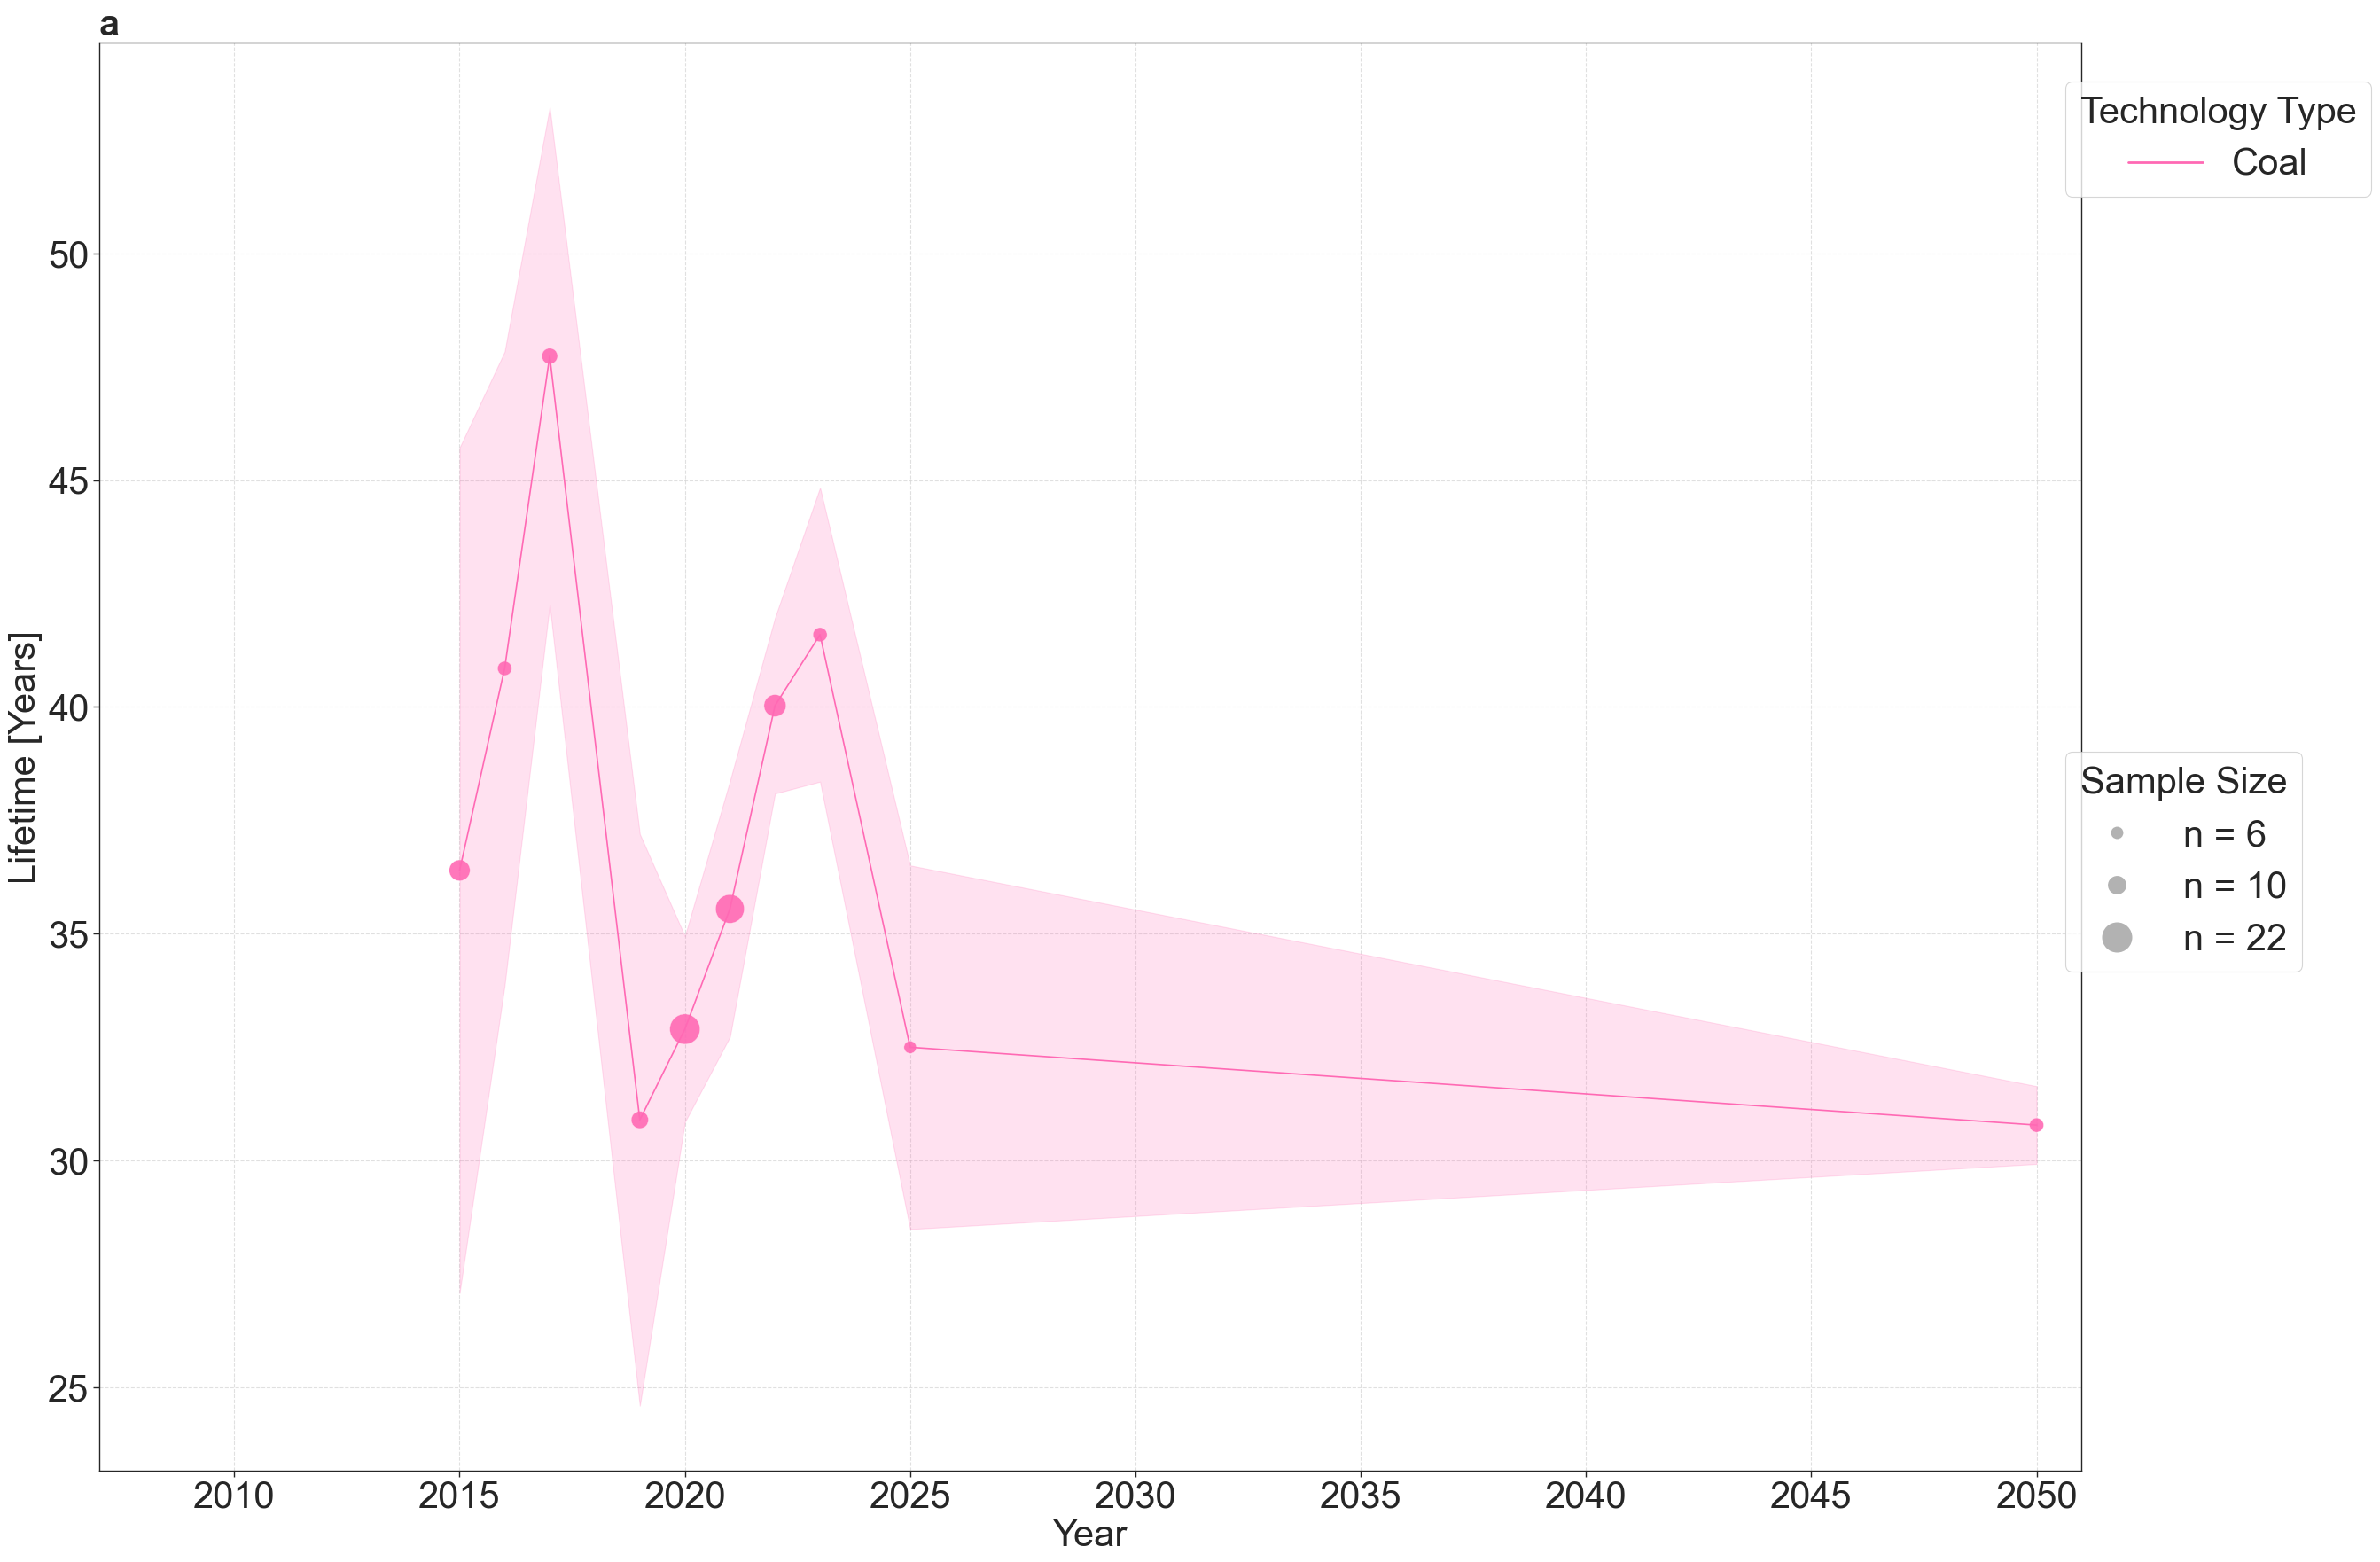

In [17]:
data = [
    {
    'df': lifetime[lifetime["entity_base_mapping"].isin(['Coal'])],
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Lifetime [Years]',
     'title': 'a',
     'year_range': (2007, 2051)
    },
]


fig, data_tables = visualisation.plot_multiple_properties_over_time(
    data_list = data,
    legend_title = 'Technology Type',
    color_dict=visualisation.entity_colors,
    figsize=(24,18),
    legend_position=(0.97,0.95),
    legend_size_position=(0.97,0.53),
    central_tendency="moving average",
    error_type="se",
    error_display="shade",
    font_size=30,
    min_papers_per_year=5,
    point_size_range=(100, 600),
    )

fig.show()

In [18]:
data_tables['a'][data_tables['a']["entity_base_mapping"] == 'Coal'].sort_values("jahr")

,jahr,entity_base_mapping,value_normalized,value_central,n,std_dev,n_window,se
0,2015,Coal,27.083333,36.398810,12.0,13.174073,2.0,9.315476
1,2016,Coal,45.714286,40.849206,7.0,12.091162,3.0,6.980835
2,2017,Coal,49.75,47.732143,8.0,9.492361,3.0,5.480417
4,2019,Coal,31.666667,30.899924,9.0,10.910072,3.0,6.298933
5,2020,Coal,30.133182,32.899949,22.0,3.547985,3.0,2.048430
6,2021,Coal,36.9,35.549522,20.0,4.883225,3.0,2.819331
7,2022,Coal,39.615385,40.028938,13.0,3.354886,3.0,1.936944
8,2023,Coal,43.571429,41.593407,7.0,5.610340,3.0,3.239132
10,2025,Coal,32.5,32.500000,6.0,6.940098,3.0,4.006868
35,2050,Coal,30.785714,30.785714,7.0,1.212183,2.0,0.857143


In [19]:
lifetime[(lifetime["entity_base_mapping"].isin(['Coal'])) &(lifetime["publication_year"] == 2016)]

,publication_year,DOI,classification,entity,property,quantity_text,value_normalized,unit_normalized,quantity_normalized,quote,...,spatial_scope_refined,unit_dimension,value_normalized_adapted,unit_normalized_adapted,unit_dimension_adapted,references,entity_mapping,entity_base_mapping,property_mapping,property_base_mapping
301132,2016,10.1051/e3sconf/20161000079,"{'rational': None, 'system': 'real_world', 'type': 'observation'}",coal,lifespan,~ 150 years,150.0,"[{'exponent': 1.0, 'text': 'years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]","{'quantities': [{'modifier': '~', 'unit': [{'exponent': 1.0, 'text': 'years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}], 'value': 150.0}], 'type': 'single_quantity'}","It is estimated that the global crude oil and natural gas deposits are going to be depleted in around 50 years, while those of coal in around 150 years.",...,<NA>,A0E0L0I0M0H0T1D0,150.0,"[{""text"": ""years"", ""exponent"": 1, ""unit_uri"": ""http://qudt.org/vocab/unit/YR"", ""year"": null}]",A0E0L0I0M0H0T1D0,None,Coal,Coal,Lifetime,Lifetime
315428,2016,10.1016/j.rser.2015.10.078,"{'rational': None, 'system': 'real_world', 'type': 'observation'}",Coal,lifetime,> 100 years,100.0,"[{'exponent': 1.0, 'text': 'years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]","{'quantities': [{'modifier': '>', 'unit': [{'exponent': 1.0, 'text': 'years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}], 'value': 100.0}], 'type': 'single_quantity'}","Mines are located in central Kazakhstan principally in the 2000km 2 Karaganda [28] and 63km 2 Ekibustuz basin coalfields [29] and the sector is said to have enough reserves to last over 100 years [30] . In the east, southeast and southwest of the country, there are smaller deposits of coal, but to date these have been poorly exploited. Coal production is currently 120 Mt of which 97 Mt (80%) is consumed domestically for electricity and heat production in thermal power plants with the remaining 22 Mt exported, as shown in Fig.",...,"{""text"": ""central Kazakhstan"", ""country"": ""Kazakhstan"", ""latitude"": 48.0098, ""longitude"": 67.46185}",A0E0L0I0M0H0T1D0,100.0,"[{""text"": ""years"", ""exponent"": 1, ""unit_uri"": ""http://qudt.org/vocab/unit/YR"", ""year"": null}]",A0E0L0I0M0H0T1D0,"[{'title': 'Prospects for coal and clean coal technologies in Kazakhstan', 'venue': ''}]",Coal,Coal,Lifetime,Lifetime
320574,2016,10.1016/j.apenergy.2015.10.016,"{'rational': 'arbitrary', 'system': 'model', 'type': 'observation'}",typical coal energy system,lifetime,= 40years,40.0,"[{'exponent': 1.0, 'text': 'years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]","{'quantities': [{'modifier': '=', 'unit': [{'exponent': 1.0, 'text': 'years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}], 'value': 40.0}], 'type': 'single_quantity'}",,...,<NA>,A0E0L0I0M0H0T1D0,40.0,"[{""text"": ""years"", ""exponent"": 1, ""unit_uri"": ""http://qudt.org/vocab/unit/YR"", ""year"": null}]",A0E0L0I0M0H0T1D0,None,Coal,Coal,Lifetime,Lifetime
320577,2016,10.1016/j.apenergy.2015.10.016,"{'rational': 'arbitrary', 'system': 'model', 'type': 'observation'}",coal energy system,lifetime,= 40years,40.0,"[{'exponent': 1.0, 'text': 'years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]","{'quantities': [{'modifier': '=', 'unit': [{'exponent': 1.0, 'text': 'years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}], 'value': 40.0}], 'type': 'single_quantity'}",,...,<NA>,A0E0L0I0M0H0T1D0,40.0,"[{""text"": ""years"", ""exponent"": 1, ""unit_uri"": ""http://qudt.org/vocab/unit/YR"", ""year"": null}]",A0E0L0I0M0H0T1D0,None,Coal,Coal,Lifetime,Lifetime
346680,2016,10.1016/j.apenergy.2015.12.006,"{'rational': 'arbitrary', 'system': 'model', 'type': 'observation'}",reference ultra-supercritical (USC) pulverized coal fired electricity generation technology,lifetime,= 40years,40.0,"[{'exponent': 1.0, 'text': 'years', 'unit_uri': 'http://qudt.org/voca